# Simulation and Validation

**Estimated time**: 15-20 minutes

**Prerequisites**: [02_spatial_rate_maps.ipynb](02_spatial_rate_maps.ipynb)

Can a rate-map estimator recover a known firing pattern from finite spikes?
Build a small recording with known Gaussian fields, inspect sampling, and
compare recovered maps with their generating models. Then repeat the analysis
on a short observation window to see why unavailable metrics need their own
status. Nothing in this workflow requires every simulated unit to pass.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rates
from neurospatial.simulation import (
    PlaceCellModel,
    SimulationSession,
    generate_population_spikes,
    simulate_trajectory_laps,
    validate_simulation,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import OKABE_ITO, apply_style

apply_style(figsize=(11, 5))

## Define the experiment before drawing spikes

Geometry is a known 100 cm track with 2 cm bins. Ten one-way traversals
alternate direction; speed is in cm/s and timestamps are in seconds.
Separate random streams govern movement and spike generation. Model centers
are fixed, so a seed never selects a favorable field placement.

In [2]:
env = Environment.from_grid_mask(
    np.ones(50, dtype=bool), grid_edges=(np.linspace(0.0, 100.0, 51),)
)
env.units = "cm"
trajectory_stream, spike_stream = np.random.SeedSequence(2026).spawn(2)
trajectory_seed = int(trajectory_stream.generate_state(1)[0])
spike_seed = int(spike_stream.generate_state(1)[0])
positions, times = simulate_trajectory_laps(
    env,
    n_laps=10,
    speed_mean=15.0,
    speed_std=2.0,
    sampling_frequency=50.0,
    pause_duration=0.5,
    seed=trajectory_seed,
)
unit_ids = np.array([101, 104, 109, 112, 118, 123])
models = [
    PlaceCellModel(
        env,
        center=np.array([center]),
        width=8.0,
        max_rate=20.0,
        baseline_rate=0.1,
    )
    for center in np.linspace(10.0, 90.0, len(unit_ids))
]
spike_times = generate_population_spikes(
    models,
    times,
    positions,
    refractory_period=0.0,
    seed=spike_seed,
    show_progress=False,
)
session = SimulationSession(
    env=env,
    positions=positions,
    times=times,
    spike_times=spike_times,
    models=models,
    unit_ids=unit_ids,
    ground_truth={
        int(label): model.ground_truth
        for label, model in zip(unit_ids, models, strict=True)
    },
    metadata={"trajectory_seed": trajectory_seed, "spike_seed": spike_seed},
)
print(f"{len(times)} tracked samples over {times[-1]:.1f} s; {len(models)} units")
print(f"Unit labels: {session.unit_ids.tolist()}")

3716 tracked samples over 74.3 s; 6 units
Unit labels: [101, 104, 109, 112, 118, 123]


These are exact piecewise-constant Poisson draws because the refractory period
is zero. A positive refractory period removes candidates and lowers realized
rates relative to the supplied model. Real recordings also have drift,
sorting errors and dependencies absent from this simulation.
For a ready-made session, `linear_track_session()` or `open_field_session()`
builds the environment, trajectory, models and spikes in one call.

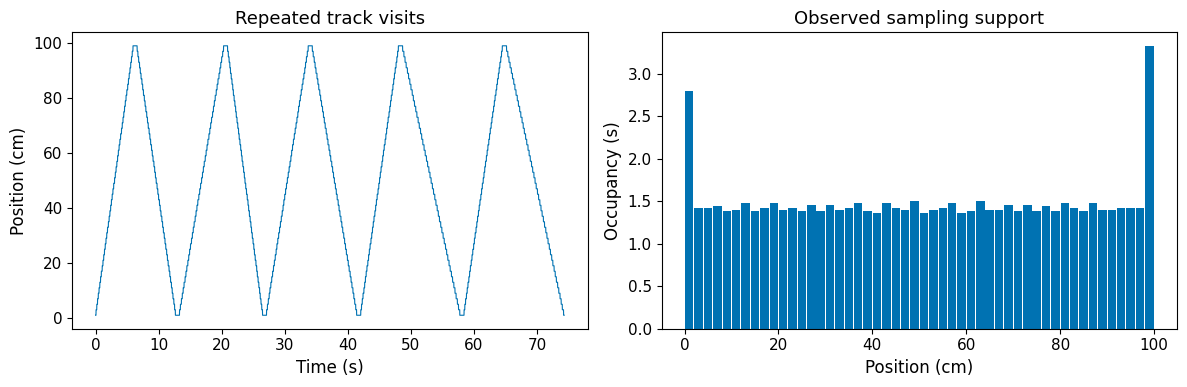

Supported bins: 50 / 50


In [3]:
recording_window = (float(times[0]), float(times[-1]))
rates = compute_spatial_rates(
    env,
    session.spike_times,
    times,
    positions,
    unit_ids=unit_ids,
    bandwidth=4.0,
    min_occupancy=0.25,
    spike_window=recording_window,
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(times, positions[:, 0], lw=0.8)
axes[0].set(xlabel="Time (s)", ylabel="Position (cm)", title="Repeated track visits")
axes[1].bar(env.bin_centers[:, 0], rates.occupancy, width=1.8)
axes[1].set(
    xlabel="Position (cm)", ylabel="Occupancy (s)", title="Observed sampling support"
)
fig.tight_layout()
plt.show()
print(f"Supported bins: {rates.spatial_support.sum()} / {env.n_bins}")

## Inspect recovered maps before a pass/fail summary

The dashed curves are model rates evaluated at spatial-bin centers. Solid
curves are estimated from spikes and occupancy; missing support remains NaN.
Smoothing changes peak height and width, so perfect agreement is not expected.

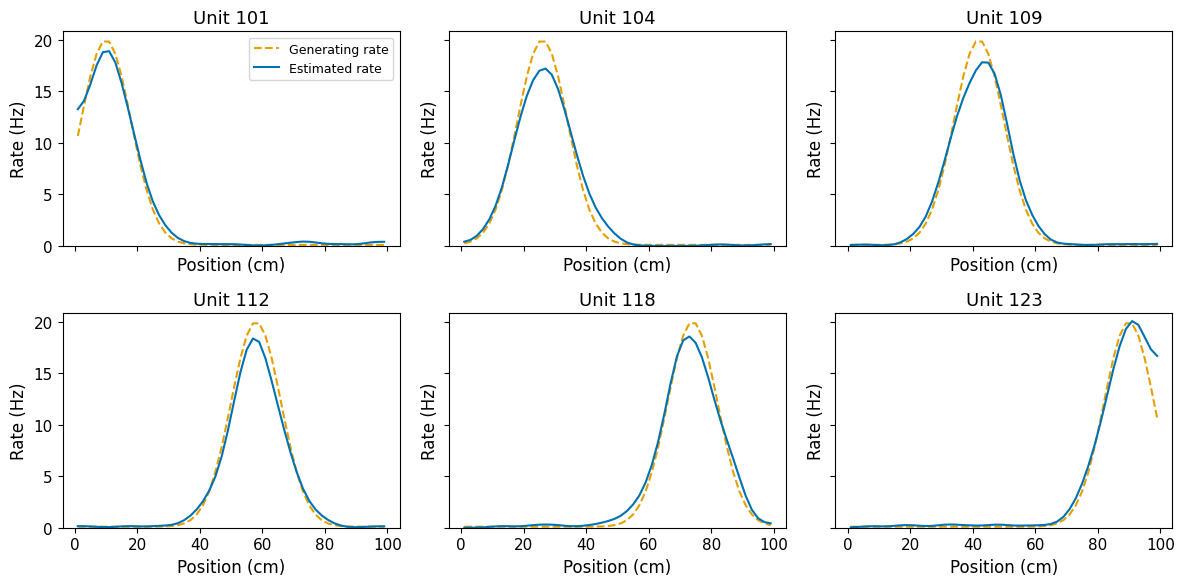

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for row, (model, label, ax) in enumerate(zip(models, unit_ids, axes.flat, strict=True)):
    ax.plot(
        env.bin_centers[:, 0],
        model.firing_rate(env.bin_centers),
        color=OKABE_ITO[1],
        ls="--",
        label="Generating rate",
    )
    ax.plot(env.bin_centers[:, 0], rates.firing_rates[row], label="Estimated rate")
    ax.set(
        title=f"Unit {label}",
        xlabel="Position (cm)",
        ylabel="Rate (Hz)",
        ylim=(0, None),
    )
axes.flat[0].legend(fontsize=9)
fig.tight_layout()
plt.show()

## Apply a stated recovery criterion

Fix the criteria here: peak-location error at most 4 cm and map correlation
at least 0.7. `validate_simulation` compares the estimated peak with the known
center, and computes correlation only over jointly finite spatial bins. It
validates map recovery, rather than testing whether a biological cell belongs
to a class. `not_evaluable` means a required metric is unavailable.

In [5]:
validation_settings = {
    "bandwidth": 4.0,
    "min_occupancy": 0.25,
    "max_center_error": 4.0,
    "min_correlation": 0.7,
}
report = validate_simulation(
    session, spike_window=recording_window, **validation_settings
)


def print_unit_report(validation):
    """Keep unavailable outcomes visible beside their unit labels."""
    print("Unit  Spikes  Peak error (cm)  Correlation  Status          Reason")
    for row, label in enumerate(validation["unit_ids"]):
        print(
            f"{label:4d}  {validation['spike_counts'][row]:6d}  "
            f"{validation['center_errors'][row]:15.2f}  "
            f"{validation['correlations'][row]:11.3f}  "
            f"{validation['unit_status'][row]:14s}  "
            f"{validation['skip_reasons'][row] or '-'}"
        )
    print(f"Evaluated: {validation['n_evaluated']} / {validation['n_selected']}")
    print(f"Every selected unit passed both criteria: {validation['passed']}")


print_unit_report(report)

Unit  Spikes  Peak error (cm)  Correlation  Status          Reason
 101     290             1.00        0.997  passed          -
 104     286             1.00        0.993  passed          -
 109     292             1.00        0.993  passed          -
 112     272             1.00        0.999  passed          -
 118     300             1.00        0.995  passed          -
 123     317             1.00        0.988  passed          -
Evaluated: 6 / 6
Every selected unit passed both criteria: True


## Reduce observation time without changing the experiment

Use the first 2 seconds of this same recording, selected in advance. Crop
tracking and spikes together and keep the original unit labels, including
units with zero spikes. A correlation can be undefined, or misleadingly high
over a small observed region; inspect coverage alongside each status.

In [6]:
short_samples = times < 2.0
short_times = times[short_samples]
short_window = (float(short_times[0]), float(short_times[-1]))
short_session = replace(
    session,
    times=short_times,
    positions=positions[short_samples],
    spike_times=[
        train[(train >= short_window[0]) & (train < short_window[1])]
        for train in spike_times
    ],
)
short_report = validate_simulation(
    short_session, spike_window=short_window, **validation_settings
)
print_unit_report(short_report)
short_occupancy = env.occupancy(
    short_times, short_session.positions, return_seconds=True
)
print(f"Bins visited in the short window: {(short_occupancy > 0).sum()} / {env.n_bins}")

Unit  Spikes  Peak error (cm)  Correlation  Status          Reason
 101      21              nan          nan  not_evaluable   no_finite_rate_bins
 104      19              nan          nan  not_evaluable   no_finite_rate_bins
 109       2              nan          nan  not_evaluable   no_finite_rate_bins
 112       0              nan          nan  not_evaluable   no_spikes
 118       0              nan          nan  not_evaluable   no_spikes
 123       0              nan          nan  not_evaluable   no_spikes
Evaluated: 0 / 6
Every selected unit passed both criteria: False
Bins visited in the short window: 17 / 50


/var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/ipykernel_47350/2747758763.py:13: UserWarning: min_occupancy=0.25 s masks ALL 17 occupied bins (the highest occupancy is 0.14 s), so the rate map will be empty (all-NaN, or all-fill_value). min_occupancy is a threshold in SECONDS -- this usually means it is too large for this session. Lower it (or use the default 0.0 for no occupancy masking).
  short_report = validate_simulation(
/var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/ipykernel_47350/2747758763.py:13: UserWarning: No cells could be fully validated (6 selected). Inspect skip_reasons and spike_counts for unavailable metrics.
  short_report = validate_simulation(


A failed or unavailable outcome is useful evidence about this estimator and
sampling design. In particular, the unchanged 0.25 s per-bin occupancy gate
can mask every bin of a 2 s recording even when some units emitted spikes;
the warning and `no_finite_rate_bins` status expose that limitation.
Keep the stated seeds and criteria fixed when judging this recording.
To study robustness, repeat independent spike draws or trajectories and report
the distribution of errors and the fraction not evaluable. Keep parameter
selection separate from the final simulations used to assess recovery.
Continue with [held-out position decoding](06_position_decoding.ipynb).